# Polynomial Interpolation

**Seong Cho** · ACME Volume 2, Lab 9

**Lab objective:** learn and compare three methods of polynomial interpolation (standard Lagrange, Barycentric Lagrange and Chebyshev interpolation), explore Runge's phenomenon and how the choice of interpolating points affects the results, and use polynomial interpolation to study air pollution by approximating graphs of particulates in air.

<sub>Lab specification from the *Volume 2* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la
from scipy.interpolate import BarycentricInterpolator

## Polynomial Interpolation

Polynomial interpolation finds a polynomial that matches a function at specific points in its range: if $f(x)$ is a function on $[a, b]$ and $p(x)$ is a polynomial, then $p(x)$ interpolates $f(x)$ at the points $x_0, x_1, \ldots, x_n$ if $p(x_j) = f(x_j)$ for all $j = 0, 1, \ldots, n$. This lab focuses on interpolation as a way of approximating functions or data, but it is useful in a much wider array of applications.

Given a function $f(x)$ and a set of unique points $\{x_i\}_{i=0}^n$, there is one and only one polynomial of degree $n$ that interpolates $f(x)$ through those points. Because of this uniqueness it is called *the* interpolating polynomial. One approach to finding it is Lagrange interpolation.

### Lagrange interpolation

Given a set $\{x_i\}_{i=1}^n$ of $n$ points to interpolate, construct a family of $n$ basis functions with the property

$$L_j(x_i) = \begin{cases} 0 & \text{if } i \neq j \\ 1 & \text{if } i = j \end{cases}.$$

Combined with the $y$-values $y_i = f(x_i)$ of the function to be interpolated,

$$p(x) = \sum_{j=1}^n y_jL_j(x) \tag{9.1}$$

is the unique interpolating polynomial. The Lagrange form of the basis functions is

$$L_j(x) = \frac{\prod_{k=1, k \neq j}^n (x - x_k)}{\prod_{k=1, k \neq j}^n (x_j - x_k)}. \tag{9.2}$$

Each $L_j$ is of degree $n - 1$ and has the property above. Lagrange interpolation consists of computing the basis functions, then combining them with the $y$-values.

Since polynomials are typically represented in expanded form with a coefficient on each term, it may seem best to use SymPy or NumPy's `poly1d` class to compute the coefficients of the interpolating polynomial. This is rarely the best approach: expanding the large polynomials that are required can quickly lead to instability, especially with many interpolating points. It is usually best to leave the polynomials in unexpanded form (still a polynomial, just not a pretty-looking one) and evaluate them directly from that form.

In [2]:
# Evaluate the polynomial (x-2)(x+1) at 10 points without expanding the expression.
pts = np.arange(10)
(pts - 2) * (pts + 1)

array([-2, -2,  0,  4, 10, 18, 28, 40, 54, 70])

The spec prints `array([ 2, 0, 0, 2, 6, 12, 20, 30, 42, 56])` here, which are the values of $(x-2)(x-1)$; the cell evaluates the expression as written. Here there would have been no instability if the expression had been expanded, but for a large polynomial stability issues can dominate the computation. The coefficients of the interpolating polynomials are never computed explicitly in this lab, though polynomials are still being used, in a different form.

The spec's Figure 9.1 shows the interpolations of Runge's function $f(x) = \frac{1}{1 + 25x^2}$ with (a) 5 and (b) 11 equally spaced interpolating points; the Problem 1 demo below reproduces it.

## Problem 1: Lagrange interpolation

> **Problem 1.** Write a function that uses the Lagrange method to find an interpolating polynomial for a set of data points and evaluates the calculated polynomial at specified values. This function should accept two NumPy arrays which contain the $x$ and $y$ values of the interpolation points as well as a NumPy array of values (of length $m$) at which the interpolating polynomial will be evaluated. Your function should return a NumPy array of the evaluated points. The following steps will help in writing your function:
> 1. Compute the denominator of each $L_j$ (as in Equation 9.2).
> 2. Using the previous step, evaluate each $L_j$ at all points in the compuational domain (this will give you $m$ values for each of the $n$ $L_j$ functions).
> 3. Combine all of these values as in Equation 9.1, this will give you the final array of length $m$.
>
> Note that steps one and two can be done in the same loop. You may find the function `np.delete()` to be useful while writing this method.
>
> You can test your function by plotting Runge's function $f(x) = \frac{1}{1 + 25x^2}$ and your interpolating polynomial on the same plot for different values of $n$ equally spaced interpolating values then comparing your plot to the plots given in Figure 9.1.

In [3]:
def lagrange(xint, yint, points):
    """Find an interpolating polynomial of lowest degree through the points
    (xint, yint) using the Lagrange method and evaluate that polynomial at
    the specified points.

    Parameters:
        xint ((n,) ndarray): x values to be interpolated.
        yint ((n,) ndarray): y values to be interpolated.
        points((m,) ndarray): x values at which to evaluate the polynomial.

    Returns:
        ((m,) ndarray): The value of the polynomial at the specified points.
    """
    l_basis = []
    for i, x in enumerate(xint):
        denom = np.prod([x - xk for xk in xint if xk != x])
        numer = 1
        for xk in xint:
            if xk != x:
                numer *= (points - xk)
        l_basis.append(numer/denom)
    p = sum([y*l_basis[i] for i,y in enumerate(yint)])

    return p

Figure 9.1, reproduced: Runge's function and its interpolating polynomials through 5 and 11 equally spaced points.

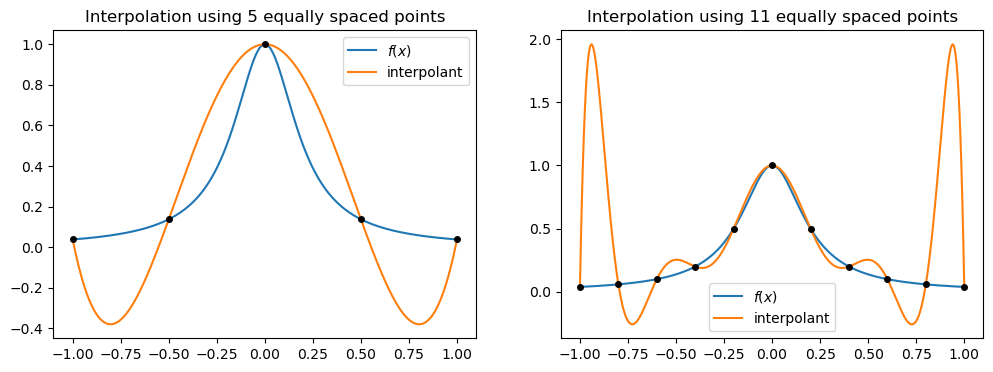

In [4]:
f = lambda x: 1/(1+25*x**2)                 # Runge's function.
domain = np.linspace(-1, 1, 400)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, n in zip(axes, [5, 11]):
    xint = np.linspace(-1, 1, n)
    ax.plot(domain, f(domain), label="$f(x)$")
    ax.plot(domain, lagrange(xint, f(xint), domain), label="interpolant")
    ax.plot(xint, f(xint), "k.", ms=8)
    ax.set_title(f"Interpolation using {n} equally spaced points")
    ax.legend()
plt.show()

Checks: the result matches SciPy's `BarycentricInterpolator`, passes through the interpolating points, and reproduces a polynomial of degree less than $n$ exactly.

In [5]:
rng = np.random.default_rng(9)
xint = np.sort(rng.uniform(-1, 1, 8))
yint = rng.normal(size=8)
pts = rng.uniform(-1, 1, 100)
assert np.allclose(lagrange(xint, yint, pts), BarycentricInterpolator(xint, yint)(pts))
assert np.allclose(lagrange(xint, yint, xint), yint)

p = np.polynomial.Polynomial([2, -1, 0, 3, 1])          # Degree 4, so 5 points determine it.
xint = np.array([-2., -0.5, 0.3, 1., 4.])
assert np.allclose(lagrange(xint, p(xint), pts), p(pts))
print("All checks passed.")

All checks passed.


The Lagrange form is useful in some theoretical contexts and is easier to understand than other methods, but it has serious drawbacks. First, Lagrange interpolation is $O(n^2)$ where other interpolation methods are $O(n^2)$ (or faster) at startup but only $O(n)$ at run-time. Second, it is an unstable algorithm, which causes it to return innacurate answers when larger numbers of interpolating points are used. While useful in some situations, it is not desirable in most instances.

## Barycentric Lagrange interpolation

Barycentric Lagrange interpolation is a simple variant of Lagrange interpolation that performs much better, in both speed and stability. It is essentially a rearrangement of the order of operations. Each basis function $L_j$ can be rewritten as

$$L_j(x) = \frac{w(x)}{(x - x_j)}w_j, \qquad \text{where} \quad w(x) = \prod_{j=1}^n (x - x_j) \quad \text{and} \quad w_j = \frac{1}{\prod_{k=1, k \neq j}^n (x_j - x_k)}.$$

The $w_j$ are the *barycentric weights*. The interpolating polynomial becomes

$$p(x) = w(x)\sum_{j=1}^n \frac{w_jy_j}{x - x_j},$$

the *first barycentric form*. Since $1 = w(x)\sum_{j=1}^n \frac{w_j}{x - x_j}$, the computation of $w(x)$ can be avoided:

$$p(x) = \frac{\displaystyle\sum_{j=1}^n \frac{w_jy_j}{x - x_j}}{\displaystyle\sum_{j=1}^n \frac{w_j}{x - x_j}}.$$

This *second barycentric form* is the one used in Barycentric Lagrange interpolation. Once the weights are known the algorithm is $O(n)$. Two more adjustments make it numerically stable, and later discussion allows the quick addition of new interpolating points after startup.

Any factor common to all the $w_k$ can be ignored, since it appears in both the numerator and the denominator. To prevent overflow, each factor of $\prod_{k \neq j}(x_j - x_k)$ is multiplied by $C^{-1}$, where $4C$ is the width of the interval being interpolated ($C$ is the *capacity* of the interval). This scales each weight by $C^{1-n}$, which cancels in the final quotient:

$$w_j = \frac{1}{\prod_{k=1, k \neq j}^n \left[(x_j - x_k)C\right]}.$$

(The formula multiplies by $C$, but the text above and the code below divide each factor by $C$, which is what scales the weights by $C^{1-n}$.) The order of the product is also randomized, so that points of similar magnitude are not all multiplied together at once, which can overflow. With both fixes the Barycentric Algorithm is numerically stable. The spec's code, run on 11 equally spaced points:

In [6]:
xint = np.linspace(-1, 1, 11)       # An example array of interpolating x-values.
np.random.seed(0)

# Given a NumPy array xint of interpolating x-values, calculate the weights.
n = len(xint)                       # Number of interpolating points.
w = np.ones(n)                      # Array for storing barycentric weights.
# Calculate the capacity of the interval.
C = (np.max(xint) - np.min(xint)) / 4

shuffle = np.random.permutation(n-1)
for j in range(n):
    temp = (xint[j] - np.delete(xint, j)) / C
    temp = temp[shuffle]            # Randomize order of product.
    w[j] /= np.prod(temp)           # The spec's np.product() was removed in NumPy 2.0.
w

array([ 0.00262807, -0.02628071,  0.11826318, -0.31536849,  0.55189486,
       -0.66227383,  0.55189486, -0.31536849,  0.11826318, -0.02628071,
        0.00262807])

## Problem 2: The `Barycentric` class

> **Problem 2.** Create a class that performs Barycentric Lagrange interpolation. The constructor of your class should accept two NumPy arrays which contain the $x$ and $y$ values of the interpolation points. Store these arrays as attributes. In the constructor, compute the corresponding barycentric weights and store the resulting array as a class attribute. Be sure that the relative ordering of the arrays remains unchanged.
>
> Implement the `__call__()` method so that it accepts a NumPy array of values at which to evaluate the interpolating polynomial and returns an array of the evaluated points. Your class can be tested in the same way as the Lagrange function written in Problem 1.

The class below also contains the Problem 3 method `add_weights()`. The weights are stored in the attribute `weights` and the points in `xint` and `yint`.

In [7]:
class Barycentric:
    """Class for performing Barycentric Lagrange interpolation.

    Attributes:
        weights ((n,) ndarray): Array of Barycentric weights.
        n (int): Number of interpolation points.
        xint ((n,) ndarray): x values of interpolating points.
        yint ((n,) ndarray): y values of interpolating points.
        C (float): The capacity of the interval (a quarter of its width).
    """

    def __init__(self, xint, yint):
        """Calculate the Barycentric weights using initial interpolating points.

        Parameters:
            xint ((n,) ndarray): x values of interpolating points.
            yint ((n,) ndarray): y values of interpolating points.
        """
        self.xint = xint
        self.yint = yint
        self.n = len(xint)
        w = np.ones(self.n)
        self.C = (np.max(xint) - np.min(xint)) / 4
        shuffle = np.random.permutation(self.n - 1)
        for j in range(self.n):
            temp = (xint[j] - np.delete(xint,j)) / self.C
            temp = temp[shuffle]
            w[j] /= np.prod(temp)       # Changed: np.product -> np.prod (np.product was removed in NumPy 2.0).
        self.weights = w

    def __call__(self, points):
        """Using the calcuated Barycentric weights, evaluate the interpolating polynomial
        at points.

        Parameters:
            points ((m,) ndarray): Array of points at which to evaluate the polynomial.

        Returns:
            ((m,) ndarray): Array of values where the polynomial has been computed.
        """
        denom = sum([self.weights[i]/(points - self.xint[i]) for i in range(self.n)])
        numer = sum([self.yint[i]*self.weights[i]/(points - self.xint[i]) for i in range(self.n)])
        return numer/denom

    # Problem 3
    def add_weights(self, xint, yint):
        """Update the existing Barycentric weights using newly given interpolating points
        and create new weights equal to the number of new points.

        Parameters:
            xint ((m,) ndarray): x values of new interpolating points.
            yint ((m,) ndarray): y values of new interpolating points.
        """
        for x in xint:
            self.n += 1
            shuffle = np.random.permutation(self.n - 1)
            temp = (x - self.xint) / self.C
            temp = temp[shuffle]
            w = 1 / np.prod(temp)       # Changed: np.product -> np.prod (np.product was removed in NumPy 2.0).
            self.weights /= (self.xint - x)/self.C
            self.weights = np.append(self.weights, w)
            self.xint = np.append(self.xint, x)

        self.yint = np.append(self.yint, yint)

Checks against SciPy's `BarycentricInterpolator`: the weights agree up to a common factor (SciPy scales them differently), and the interpolants agree at random points, for equally spaced, Chebyshev and random sets of interpolating points. The evaluation points avoid the interpolating points; see the Achtung! below.

In [8]:
np.random.seed(1)
rng = np.random.default_rng(1)
pts = rng.uniform(-1, 1, 500)
for name, xint in [("equally spaced", np.linspace(-1, 1, 15)),
                   ("Chebyshev",      np.cos(np.arange(31) * np.pi / 30)),
                   ("random",         rng.uniform(-1, 1, 10))]:
    B = Barycentric(xint, f(xint))
    S = BarycentricInterpolator(xint, f(xint))
    assert np.allclose(B.weights / B.weights[0], S.wi / S.wi[0])
    assert np.allclose(B(pts), S(pts))
    assert np.allclose(B(pts), lagrange(xint, f(xint), pts))
    print(f"{name:15} max |B - scipy| = {np.max(np.abs(B(pts) - S(pts))):.1e}")

equally spaced  max |B - scipy| = 2.1e-13
Chebyshev       max |B - scipy| = 5.0e-16
random          max |B - scipy| = 1.1e-07


> **Achtung!** As currently explained and implemented, the Barycentric class from Problem 2 will fail when a point to be evaluated exactly matches one of the $x$-values of the interpolating points. This happens because a divide by zero error is encountered in the final step of the algorithm. The fix for this, although not required here, is quite easy: keep track of any problem points and replace the final computed value with the corresponding $y$-value (since this is a point that is exactly interpolated). If you do not implement this fix, just be sure not to pass in any points that exactly match your interpolating values.

The class does not include the optional fix, so an interpolating point evaluates to `nan` (with NumPy's divide-by-zero warnings):

In [9]:
B = Barycentric(np.array([-1., 0., 1.]), np.array([1., 0., 1.]))
with np.errstate(divide="ignore", invalid="ignore"):
    print(B(np.array([-0.5, 0., 0.5])))

[0.25  nan 0.25]


Another advantage of the barycentric method is that it allows the addition of new interpolating points in $O(n)$ time. Given existing barycentric weights $\{w_j\}_{j=1}^n$ and a new interpolating point $x_i$, the new barycentric weight is

$$w_i = \frac{1}{\prod_{k=1}^n (x_i - x_k)},$$

and all existing weights are updated as $w_j = \frac{w_j}{x_j - x_i}$.

## Problem 3: Adding interpolating points

> **Problem 3.** Include a method in the class written in Problem 2 that allows for the addition of new interpolating points by updating the barycentric weights. Your function should accept two NumPy arrays which contain the $x$ and $y$ values of the new interpolation points. Update and store the old weights then extend the class attribute arrays that store the weights, and the $x$ and $y$ values of the interpolation points with the new data. When updating all class attributes, make sure to maintain the same relative order.

`add_weights()` is in the class above; it applies the same capacity scaling, so the updated weights equal those computed from scratch. The `test2()` helper interpolates Runge's function at every other one of 15 equally spaced points, plots the result, adds the remaining points and plots again.

In [10]:
f = lambda x: 1/(1+25*x**2)

def test2():
    x = np.linspace(-1,1,15)
    y = f(x)
    dom = np.linspace(-1,1,100)
    B = Barycentric(x[::2], y[::2])

    plt.plot(dom, f(dom))
    plt.plot(dom, B(dom))
    plt.ylim((-0.3, 1.2))
    plt.show()

    B.add_weights(x[1::2], y[1::2])

    plt.plot(dom, f(dom))
    plt.plot(dom, B(dom))
    plt.show()

`test2()`'s plotting domain includes the endpoints $\pm 1$, which are interpolating points, so the curves have `nan` there (Matplotlib leaves them out); the warnings are silenced for the demo. The first plot uses 8 points, the second all 15.

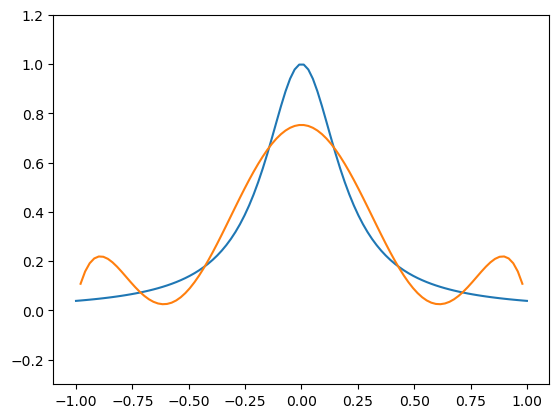

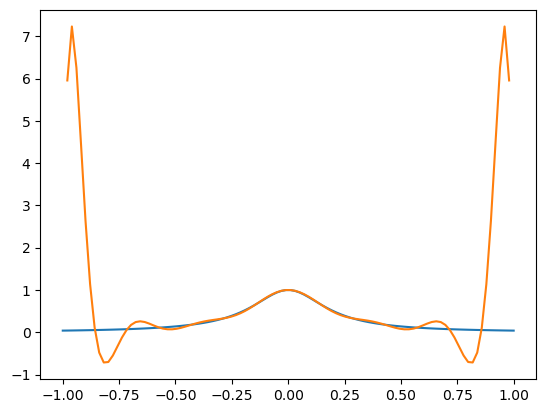

In [11]:
np.random.seed(3)
with np.errstate(divide="ignore", invalid="ignore"):
    test2()

In [12]:
np.random.seed(3)
x = np.linspace(-1, 1, 15)
B = Barycentric(x[::2], f(x[::2]))
B.add_weights(x[1::2], f(x[1::2]))
full = Barycentric(x, f(x))
order = np.argsort(B.xint)

print("xint:", B.xint)
assert len(B.xint) == len(B.yint) == len(B.weights) == B.n == 15
assert np.allclose(B.xint[order], x) and np.allclose(B.yint, f(B.xint))   # Points and values kept paired.
assert np.allclose(B.weights[order], full.weights)                           # Same weights as from scratch.
assert np.allclose(B(pts), BarycentricInterpolator(x, f(x))(pts))
print("All checks passed.")

xint: [-1.         -0.71428571 -0.42857143 -0.14285714  0.14285714  0.42857143
  0.71428571  1.         -0.85714286 -0.57142857 -0.28571429  0.
  0.28571429  0.57142857  0.85714286]
All checks passed.


The implementation outlined here calls for the $y$-values of the interpolating points to be known during startup, but these values are not needed until run-time. This allows the $y$-values to be changed without having to recompute the barycentric weights, an additional advantage of Barycentric Lagrange interpolation.

### SciPy's Barycentric Lagrange class

SciPy includes a Barycentric interpolator class with the same functionality as the class from Problems 2 and 3, plus the ability to update the $y$-values of the interpolation points. The spec's code, which produces a figure similar to Figure 9.1b:

```python
>>> from scipy.interpolate import BarycentricInterpolator

>>> f = lambda x: 1/(1+25 * x**2)   # Function to be interpolated.
# Obtain the Chebyshev extremal points on [-1,1].
>>> n = 11
>>> pts = np.linspace(-1, 1, n)
>>> domain = np.linspace(-1, 1, 200)

>>> poly = BarycentricInterpolator(pts[:-1])
>>> poly.add_xi(pts[-1])            # Oops, forgot one of the points.
>>> poly.set_yi(f(pts))             # Set the y values.

>>> plt.plot(domain, f(domain))
>>> plt.plot(domain, poly.eval(domain))
```

The comment says Chebyshev points, but the code uses equally spaced points, as in Figure 9.1b. In SciPy 1.16, `add_xi()` needs an array (a scalar raises a `ValueError`), so the cell below passes `pts[-1:]`, and the interpolator has no `eval()` method; it is called directly.

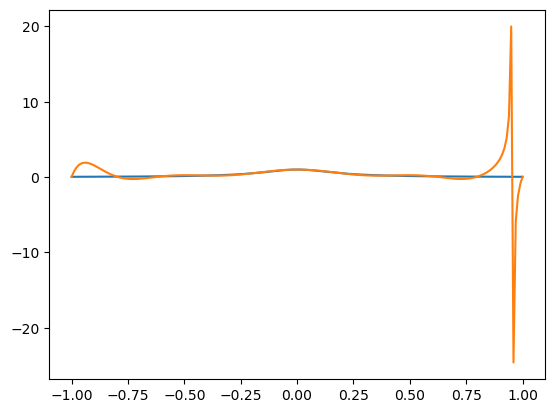

In [13]:
f = lambda x: 1/(1+25 * x**2)       # Function to be interpolated.
n = 11
pts = np.linspace(-1, 1, n)
domain = np.linspace(-1, 1, 200)

poly = BarycentricInterpolator(pts[:-1])
poly.add_xi(pts[-1:])               # Oops, forgot one of the points.
poly.set_yi(f(pts))                 # Set the y values.

plt.plot(domain, f(domain))
plt.plot(domain, poly(domain))
plt.show()

## Chebyshev Interpolation

### Chebyshev nodes

The Barycentric version of Lagrange interpolation is a stable process that does not accumulate large errors, even with extreme inputs. However, polynomial interpolation itself is, in general, an ill-conditioned problem: small changes in the interpolating values can give drastically different interpolating polynomials, and poorly chosen interpolating points can give a very bad approximation of a function. As more points are added, the approximation can worsen. This increase in error is called *Runge's phenomenon*.

Equally spaced points may seem like a reasonable choice for interpolation but in reality produce very poor results, as Figure 9.1 shows for Runge's function: as the number of interpolating points increases, the approximation deteriorates, especially near the endpoints.

A good set of interpolating points, however, can give fast convergence to the original function as points are added. One such set is the *Chebyshev extremal points*, related to the Chebyshev polynomials discussed below. The $n + 1$ Chebyshev extremal points on $[a, b]$ are

$$y_j = \tfrac{1}{2}\left(a + b + (b - a)\cos\left(\tfrac{j\pi}{n}\right)\right), \quad j = 0, 1, \ldots, n.$$

They are clustered near the endpoints of the interval, which is key to preventing Runge's phenomenon. (The spec's Figure 9.2 shows the interpolants of Runge's function through 5 and 11 Chebyshev points overcoming Runge's phenomenon, and Figure 9.3 shows the extremal points as the projection onto the $x$-axis of equally spaced points around the unit circle.)

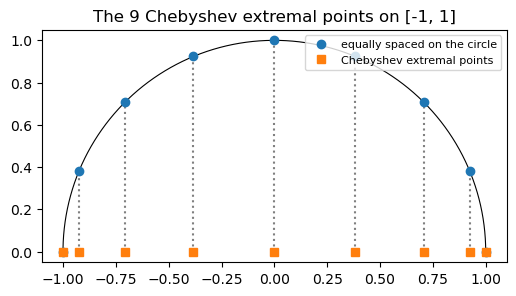

In [14]:
n = 8
theta = np.arange(n+1) * np.pi / n
plt.figure(figsize=(6, 3.5))
plt.plot(np.cos(np.linspace(0, np.pi, 200)), np.sin(np.linspace(0, np.pi, 200)), "k-", lw=0.8)
plt.vlines(np.cos(theta), 0, np.sin(theta), colors="gray", linestyles=":")
plt.plot(np.cos(theta), np.sin(theta), "o", label="equally spaced on the circle")
plt.plot(np.cos(theta), np.zeros(n+1), "s", label="Chebyshev extremal points")
plt.gca().set_aspect("equal")
plt.legend(loc="upper right", fontsize=8)
plt.title(f"The {n+1} Chebyshev extremal points on [-1, 1]")
plt.show()

## Problem 4: Runge's phenomenon

> **Problem 4.** Write a function that defines a domain $x$ of 400 equally spaced points on the interval $[-1, 1]$. For $n = 2^2, 2^3, \ldots, 2^8$, repeat the following experiment.
> 1. Interpolate Runge's function $f(x) = 1/(1 + 25x^2)$ with $n$ equally spaced points over $[-1, 1]$ using SciPy's `BarycentricInterpolator` class, resulting in an approximating function $\tilde{f}$. Compute the absolute error $\|f(x) - \tilde{f}(x)\|_\infty$ of the approximation using `la.norm()` with `ord=np.inf`.
> 2. Interpolate Runge's function with $n + 1$ Chebyshev extremal points, also via SciPy, and compute the absolute error.
>
> Plot the errors of each method against the number of interpolating points $n$ in a log-log plot.
>
> To verify that your figure make sense, try plotting the interpolating polynomials with the original function for a few of the larger values of $n$.

In [15]:
def prob4():
    """For n = 2^2, 2^3, ..., 2^8, calculate the error of intepolating Runge's
    function on [-1,1] with n points using SciPy's BarycentricInterpolator
    class, once with equally spaced points and once with the Chebyshev
    extremal points. Plot the absolute error of the interpolation with each
    method on a log-log plot.
    """
    domain = np.linspace(-1, 1, 400)
    n_array = [2**i for i in range(2,9)]
    f = lambda x: 1 / (1 + 25*x**2)
    plt.ion()
    poly_error = []
    cheby_error = []
    for n in n_array:
        x = np.linspace(-1, 1, n)
        poly = BarycentricInterpolator(x)
        poly.set_yi(f(x))
        # Changed: check_finite=False. With SciPy 1.16 the 128- and 256-point equally spaced
        # interpolants often evaluate to inf/nan (the weights span ~40 orders of magnitude and
        # the denominator cancels to 0; it depends on SciPy's random weight ordering), and
        # la.norm() then raised a ValueError. Such an error is now inf/nan, left off the plot.
        poly_error.append(la.norm(f(domain) - poly(domain), ord=np.inf, check_finite=False))
        y = np.array([(1/2)*(2*np.cos(j*np.pi/n)) for j in range(n+1)])
        cheby = BarycentricInterpolator(y)
        cheby.set_yi(f(y))
        cheby_error.append(la.norm(f(domain) - cheby(domain), ord=np.inf))
    plt.loglog(n_array, poly_error, label="equally spaced points", base=2)       # Changed: basex=2 -> base=2;
    plt.loglog(n_array, cheby_error, label="Chebyshev extremal points", base=2)  # Matplotlib 3.5 removed basex.
    plt.legend()
    plt.show()

SciPy shuffles the order of the products in its weights with NumPy's global random state, and on SciPy 1.16 most seeds make the 128- or 256-point equally spaced interpolant evaluate to `inf` or `nan` somewhere on the domain, which the original `la.norm()` call rejected. The seed below is one for which every interpolant is finite, so all seven points appear.

Up to 64 points the computed equally spaced errors track the true ones in magnitude (a 120-digit `mpmath` computation gives about 2.1, 705 and $1.4 \times 10^{8}$ for 16, 32 and 64 points). The true errors for 128 and 256 points are about $9 \times 10^{18}$ and $10^{40}$, but there the double-precision evaluation breaks down (the weights span dozens of orders of magnitude and the sums cancel), so the values plotted for those two sizes are rounding noise, not the interpolation error. The Chebyshev error falls steadily toward machine precision.

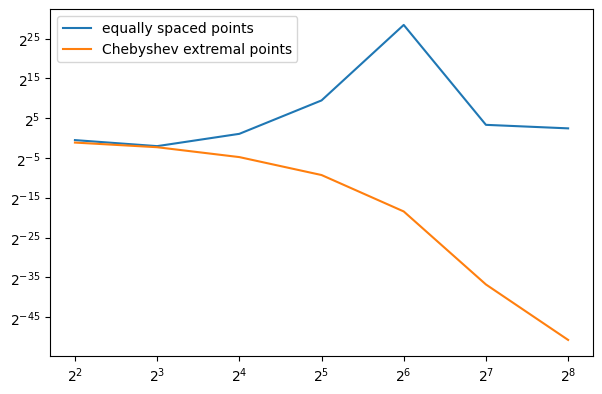

In [16]:
np.random.seed(5)
plt.figure(figsize=(7, 4.5))
prob4()

The interpolating polynomials for $n = 16$ (equally spaced, left) and $n + 1 = 17$ Chebyshev extremal points (right), compare Figures 9.1 and 9.2. The equally spaced interpolant oscillates wildly near the endpoints, while the Chebyshev interpolant is already close to $f$.

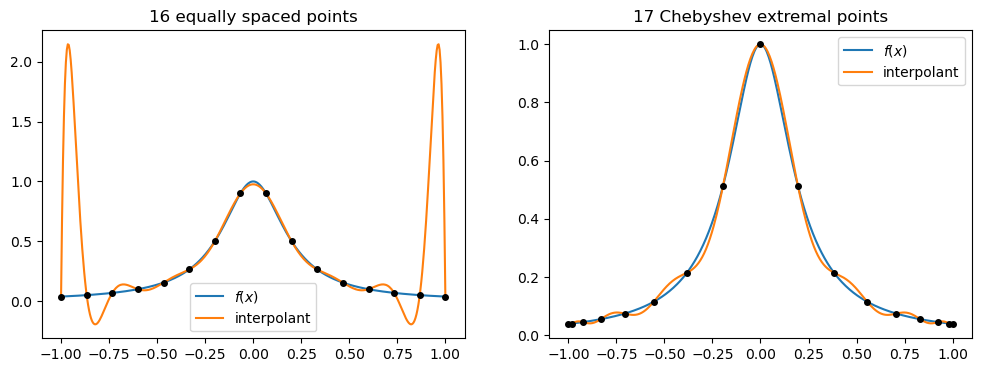

In [17]:
np.random.seed(6)
f = lambda x: 1/(1+25*x**2)
domain = np.linspace(-1, 1, 400)
n = 16
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, xint) in zip(axes, [("equally spaced", np.linspace(-1, 1, n)),
                                   ("Chebyshev extremal", np.cos(np.arange(n+1) * np.pi / n))]):
    poly = BarycentricInterpolator(xint, f(xint))
    ax.plot(domain, f(domain), label="$f(x)$")
    ax.plot(domain, poly(domain), label="interpolant")
    ax.plot(xint, f(xint), "k.", ms=8)
    ax.set_title(f"{len(xint)} {name} points")
    ax.legend()
plt.show()

### Chebyshev polynomials

The Chebyshev roots and extremal points are closely related to the *Chebyshev polynomials*, defined by $T_0(x) = 1$, $T_1(x) = x$, and the recursion $T_{n+1}(x) = 2xT_n(x) - T_{n-1}(x)$. They form a complete basis for the polynomials in $\mathbb{R}$, so every polynomial $p(x)$ has unique coefficients $\{a_k\}_{k=0}^n$ with

$$p(x) = \sum_{k=0}^n a_kT_k.$$

Finding the Chebyshev representation of an interpolating polynomial is a slow process (dominated by matrix multiplication or solving a linear system), but when the interpolating values are the Chebyshev extrema, there is a fast algorithm based on the Fast Fourier transform, with temporal complexity $O(n \log n)$. Given the $n + 1$ Chebyshev extremal points $y_j = \cos\left(\frac{j\pi}{n}\right)$ for $j = 0, 1, \ldots, n$ and a function $f$, the unique degree-$n$ interpolating polynomial is $p(x) = \sum_{k=0}^n a_kT_k$, where

$$a_k = \gamma_k \Re\left[\operatorname{DFT}\left(f(y_0), f(y_1), \ldots, f(y_{2n-1})\right)\right]_k.$$

Although this formulation includes $y_j$ for $j > n$, there are really only $n + 1$ distinct values, since $y_{n-k} = y_{n+k}$. Here $\Re$ denotes the real part of the Fourier transform and

$$\gamma_k = \begin{cases} 1 & k \in \{0, n\} \\ 2 & \text{otherwise.} \end{cases}$$

## Problem 5: Chebyshev coefficients

> **Problem 5.** Write a function that accepts a function $f$ and an integer $n$. Compute the $n + 1$ Chebyshev coefficients for the degree $n$ interpolating polynomial of $f$ using the Fourier transform (`np.real()` and `np.fft.fft()` will be helpful). When using NumPy's `fft()` function, multiply every entry of the resulting array by the scaling factor $\frac{1}{2n}$ to match the derivation given above.
>
> Validate your function with `np.polynomial.chebyshev.poly2cheb()`. The results should be exact for polynomials.
>
> ```python
> # Define f(x) = -3 + 2x^2 - x^3 + x^4 by its (ascending) coefficients.
> >>> f = lambda x: -3 + 2*x**2 - x**3 + x**4
> >>> pcoeffs = [-3, 0, 2, -1, 1]
> >>> ccoeffs = np.polynomial.chebyshev.poly2cheb(pcoeffs)
>
> # The following callable objects are equivalent to f().
> >>> fpoly = np.polynomial.Polynomial(pcoeffs)
> >>> fcheb = np.polynomial.Chebyshev(ccoeffs)
> ```

The function combines the two scalings: dividing by $n$ is $\frac{1}{2n}$ times $\gamma_k = 2$, and the first and last coefficients are halved again for $\gamma_0 = \gamma_n = 1$.

In [18]:
def chebyshev_coeffs(f, n):
    """Obtain the Chebyshev coefficients of a polynomial that interpolates
    the function f at the n+1 Chebyshev extremal points.

    Parameters:
        f (function): Function to be interpolated.
        n (int): The degree of the interpolating polynomial.

    Returns:
        coeffs ((n+1,) ndarray): Chebyshev coefficients for the interpolating polynomial.
    """
    extrema = np.cos((np.pi * np.arange(2*n))/n)
    samples = f(extrema)
    coeffs = np.real(np.fft.fft(samples))[:n+1]
    coeffs /= n
    coeffs[0] /= 2
    coeffs[n] /= 2

    return coeffs

The spec's example: the coefficients match `poly2cheb()` exactly for $n = 4$, and for a larger $n$ the extra coefficients are zero. For a non-polynomial (Runge's function), the resulting Chebyshev series interpolates $f$ at the $n + 1$ extremal points.

In [19]:
# Define f(x) = -3 + 2x^2 - x^3 + x^4 by its (ascending) coefficients.
f = lambda x: -3 + 2*x**2 - x**3 + x**4
pcoeffs = [-3, 0, 2, -1, 1]
ccoeffs = np.polynomial.chebyshev.poly2cheb(pcoeffs)

# The following callable objects are equivalent to f().
fpoly = np.polynomial.Polynomial(pcoeffs)
fcheb = np.polynomial.Chebyshev(ccoeffs)
x = np.linspace(-1, 1, 7)
assert np.allclose(f(x), fpoly(x)) and np.allclose(f(x), fcheb(x))

print("poly2cheb:       ", ccoeffs)
print("chebyshev_coeffs:", chebyshev_coeffs(f, 4))
assert np.allclose(chebyshev_coeffs(f, 4), ccoeffs)
assert np.allclose(chebyshev_coeffs(f, 7), np.r_[ccoeffs, 0, 0, 0])

runge = lambda x: 1/(1+25*x**2)
for n in [8, 16, 31]:
    yj = np.cos(np.arange(n+1) * np.pi / n)
    assert np.allclose(np.polynomial.Chebyshev(chebyshev_coeffs(runge, n))(yj), runge(yj))
print("All checks passed.")

poly2cheb:        [-1.625 -0.75   1.5   -0.25   0.125]
chebyshev_coeffs: [-1.625 -0.75   1.5   -0.25   0.125]
All checks passed.


### Lagrange vs. Chebyshev

Barycentric Lagrange interpolation is $O(n^2)$ at startup and $O(n)$ at runtime, while Chebyshev interpolation is $O(n \log n)$. This improved speed is one of the greatest advantages of Chebyshev interpolation, and it is also more accurate than Barycentric interpolation, even with the same points. Despite these advantages, Barycentric Lagrange interpolation has one very important advantage: it can be used on any set of interpolating points, while Chebyshev interpolation is restricted to the Chebyshev nodes. In general the Chebyshev nodes are more desirable for interpolation because of their better accuracy, but when the Chebyshev nodes are not available or specific points are needed, Chebyshev interpolation is not possible and Barycentric Lagrange interpolation must be used.

## Utah Air Quality

The Utah Department of Environmental Quality has air quality stations throughout the state of Utah that measure the concentration of particles found in the air. One particulate of particular interest is PM2.5, a set of extremely fine particles known to cause tissue damage to the lungs. The file `airdata.npy` has the hourly concentration of PM2.5 in micrograms per cubic meter for a particular measuring station in Salt Lake County for the year 2016. The data presents a fairly smooth function which can be reasonably approximated by an interpolating polynomial.

Chebyshev interpolation would be preferable (because of its superior speed and accuracy), but it is not possible here because the data is not continous and the information at the Chebyshev nodes is not known. To get the best possible interpolation, it is still preferable to use points close to the Chebyshev extrema with Barycentric interpolation. The spec's code takes the $n + 1$ Chebyshev extrema, finds the closest match in the non-continuous data in the variable `data`, then calculates the barycentric weights:

```python
>>> fx = lambda a, b, n: .5*(a+b + (b-a) * np.cos(np.arange(n+1) * np.pi / n))
>>> a, b = 0, 366 - 1/24
>>> domain = np.linspace(0, b, 8784)
>>> points = fx(a, b, n)
>>> temp = np.abs(points - domain.reshape(8784, 1))
>>> temp2 = np.argmin(temp, axis=0)

>>> poly = barycentric(domain[temp2], data[temp2])
```

## Problem 6: Interpolating the air quality data

> **Problem 6.** Write a function that interpolates the given data along the whole interval at the closest approximations to the $n + 1$ Chebyshev extremal nodes. The function should accept $n$, perform the Barycentric interpolation then plot the original data and the approximating polynomial on the same domain on two separate subplots. Your interpolating polynomial should give a fairly good approximation starting at around 50 points. Note that beyond about 200 points, the given code will break down since it will attempt to return multiple of the same points causing a divide by 0 error. If you did not perform the fix suggested in the ACHTUNG box, make sure not to pass in any points that exactly match the interpolating values.

In [20]:
def prob6(n):
    """Interpolate the air quality data found in airdata.npy using
    Barycentric Lagrange interpolation. Plot the original data and the
    interpolating polynomial.

    Parameters:
        n (int): Number of interpolating points to use.
    """
    data = np.load('airdata.npy')
    fx = lambda a, b, n: .5*(a+b + (b-a) * np.cos(np.arange(n+1) * np.pi/n))
    a, b = 0, 366 - 1/24
    domain = np.linspace(0, b, 8784)
    pts = fx(a, b, n)
    temp = np.abs(pts - domain.reshape(8784, 1))
    temp2 = np.argmin(temp, axis=0)
    poly = Barycentric(domain[temp2], data[temp2])

    plt.ion()
    plt.subplot(121)
    plt.plot(domain, data)
    plt.title("Data")
    plt.subplot(122)
    plt.plot(domain, poly(domain))
    plt.title("Interpolation")
    plt.show()

`prob6()` evaluates the polynomial on the full domain, which contains the $n + 1$ interpolating points themselves, so the interpolant is `nan` at those points (the Achtung! case; Matplotlib leaves them out of the line). The divide-by-zero warnings are silenced for the demos. With $n = 50$ the polynomial follows the broad trend of the year; $n = 150$ picks up more of the shorter spikes.

(8784,) min -10.0, max 98.8 µg/m³


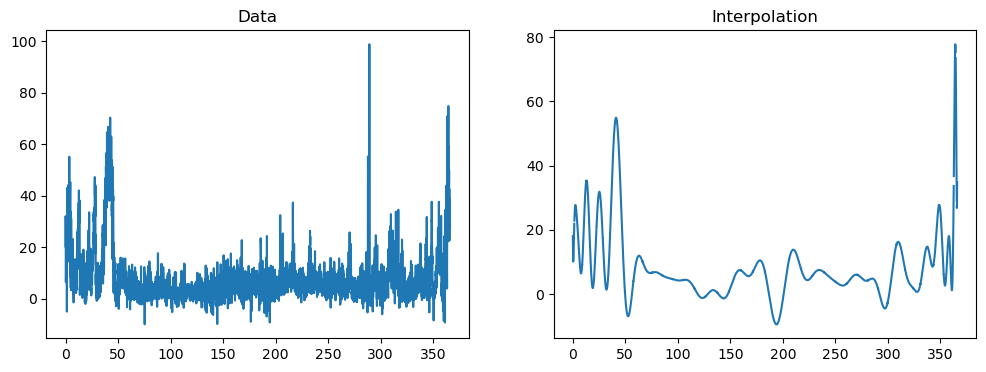

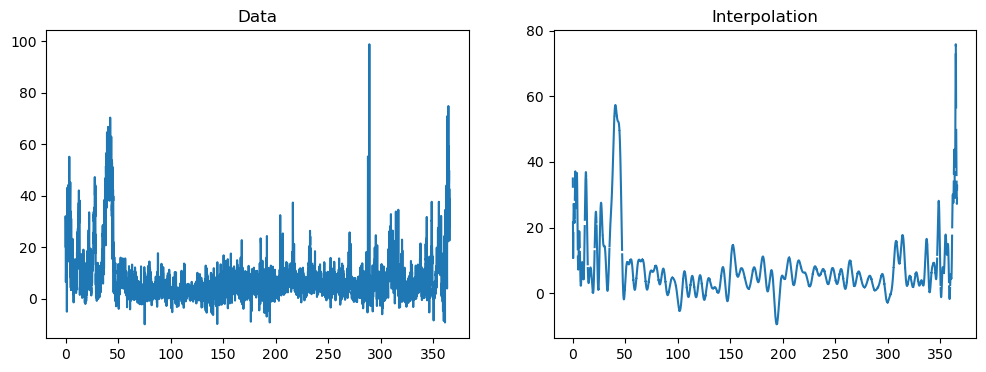

In [21]:
data = np.load('airdata.npy')
print(data.shape, f"min {data.min():.1f}, max {data.max():.1f} µg/m³")

for n in [50, 150]:
    np.random.seed(n)
    plt.figure(figsize=(12, 4))
    with np.errstate(divide="ignore", invalid="ignore"):
        prob6(n)

## Additional Material: the Clenshaw algorithm

The Clenshaw Algorithm is a fast algorithm commonly used to evaluate a polynomial given its representation in Chebyshev coefficients. It is based on the recursive relation between Chebyshev polynomials and is the algorithm used by NumPy's `polynomial.chebyshev` module.

```text
Algorithm 9.1  Accepts an array x of points at which to evaluate the polynomial
               and an array a = [a0, a1, ..., a(n-1)] of Chebyshev coefficients.
1: procedure ClenshawRecursion(x, a)
2:     u(n+1) ← 0
3:     u(n) ← 0
4:     k ← n − 1
5:     while k ≥ 1 do
6:         u(k) ← 2x·u(k+1) − u(k+2) + a(k)
7:         k ← k − 1
8:     return a0 + x·u(1) − u(2)
```